In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="llama3.2:latest")
print('Model is ready')

Model is ready


In [2]:
from typing import TypedDict

class ReflectionState(TypedDict):
    task: str
    draft: str
    critique: str
    iteration: int

print('Reflection State is ready')

Reflection State is ready


In [3]:
# Generator node
def generate(state: ReflectionState):

    if state["draft"]:
        prompt = f"""
        You are an expert technical writer.

        Original task:
        {state["task"]}

        Previous draft:
        {state["draft"]}

        Critic feedback:
        {state["critique"]}

        Improve the previous draft based on the critic's feedback.

        Return only the improved draft.
        """
    else:
        prompt = f"""
        You are an expert technical writer.

        Write a high-quality answer for the following task:

        {state["task"]}

        Return only the draft.
        """

    response = model.invoke(prompt)

    return {
        "draft": response.content,
        "iteration": state["iteration"] + 1
    }

print('Generate node is ready')

Generate node is ready


In [4]:
# Reflection/Critic node
def reflect(state: ReflectionState):

    prompt = f"""
    You are a strict reviewer.

    Review the following answer against the original task.

    Original task:
    {state["task"]}

    Draft:
    {state["draft"]}

    Analyze:

    1. Accuracy
    2. Completeness
    3. Clarity
    4. Relevance
    5. Technical quality

    If the answer is good enough, start your response with:

    PASS

    Otherwise, start your response with:

    REVISE

    Then provide detailed feedback.
    """

    response = model.invoke(prompt)

    return {
        "critique": response.content
    }

print('Reflection node is ready')

Reflection node is ready


In [5]:
# Should continue node
def should_continue(state: ReflectionState):

    critique = state["critique"]

    if critique.strip().upper().startswith("PASS"):
        return "accept"

    if state["iteration"] >= 3:
        return "accept"

    return "improve"

print('should continue is ready')

should continue is ready


Graph is ready


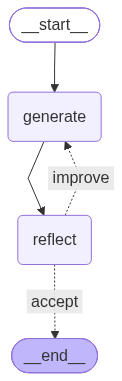

In [6]:
from langgraph.graph import StateGraph, START, END


builder = StateGraph(ReflectionState)

builder.add_node("generate", generate)
builder.add_node("reflect", reflect)

builder.add_edge(START, "generate")

builder.add_edge(
    "generate",
    "reflect"
)

builder.add_conditional_edges(
    "reflect",
    should_continue,
    {
        "improve": "generate",
        "accept": END
    }
)

graph = builder.compile()
print('Graph is ready')
graph

In [ ]:
result = graph.invoke({
    "task": """
    Please suggest few tourist places in New Delhi for 2 days tour.
    """,
    "draft": "",
    "critique": "",
    "iteration": 0
})
result